# Wilson 2025 source data

This notebook inspects the public Dryad release behind the PRI-T cursor recalibration paper. The dataset is one long series of closed-loop cursor control by BrainGate2 participant T5, recorded across 103 days between 2016 and 2021, which is what makes it useful for studying how intracortical signals drift over years.

One `.mat` file is one recording day. A day contains several back-to-back task blocks that share a single 50 Hz time base, and the task and the online decoder change from block to block.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

from neuralshed.datasets.wilson_2025 import utils

## Inventory

The release splits the days into two folders, `historical` (2016 to 2020) and `new` (2021). Both are the same recording paradigm, so `utils` treats them as one series and keeps the folder only as a label.

In [2]:
blocks = utils.list_blocks()
sessions = utils.list_sessions()

print(f"data directory: {utils.DEFAULT_DATA_DIR}")
print(f"recording days: {len(sessions)}  ({sessions[0]} to {sessions[-1]})")
print(f"task blocks: {len(blocks)}")
print("blocks per release folder:", Counter(block.group for block in blocks))
print("blocks per task:", Counter(block.task for block in blocks))

data directory: /Volumes/seagate_0/tether/datasets/wilson_2025/data/Wilson2025CursorRecalibration/PRITpaper2025/T5/raw_data
recording days: 103  (t5.2016.09.26 to t5.2021.07.26)
task blocks: 560
blocks per release folder: Counter({'historical': 503, 'new': 57})
blocks per task: Counter({'cursor': 397, 'keyboard': 103, 'fitts': 60})


The three task names are the source's own labels. All three are two-dimensional cursor-to-target acquisition, they differ in how targets are laid out on the screen.

In [3]:
for task, label in utils.TASK_LABELS.items():
    n = sum(1 for block in blocks if block.task == task)
    hours = sum(utils.duration(b) for b in blocks if b.task == task) / 3600
    print(f"{task:9s} {n:4d} blocks  {hours:5.1f} h   {label}")

total_hours = sum(utils.duration(block) for block in blocks) / 3600
total_trials = sum(len(utils.trial_windows(block)) for block in blocks)
print(f"\ntotal: {total_hours:.1f} h, {total_trials} trials")

cursor     397 blocks   30.1 h   Radial-8 / random target acquisition


keyboard   103 blocks    3.2 h   Grid target acquisition


fitts       60 blocks    4.9 h   Fitts-style random target acquisition



total: 38.2 h, 68327 trials


## The source layout

The release stores each day as a positional MATLAB struct, so fields are reached by index rather than by name. `utils.load_session` maps those indices onto named arrays, and is the only place the layout is spelled out.

In [4]:
session = utils.list_session_files()[0]
data = utils.load_session(session[2], session[0])

print(f"session {session[0]} ({session[1]})")
for key, value in data.items():
    if isinstance(value, np.ndarray):
        print(f"  {key:22s} {str(value.shape):14s} {value.dtype}")
    else:
        print(f"  {key:22s} {value}")

session t5.2016.09.26 (historical)
  block_list             (6,)           int64
  block_names            (6,)           object
  click_enabled          (6,)           bool
  block_per_bin          (50889,)       int64
  threshold_crossings    (50889, 192)   uint16
  cursor_position        (50889, 2)     float64
  target_position        (50889, 2)     float64
  decoded_velocity       (50889, 2)     float64
  decoded_click          (50889, 1)     float64
  on_target              (50889, 1)     float64
  target_size            (50889,)       float64
  cursor_size            (50889,)       float64
  system_clock           (50889,)       float64
  nsp_clock              (50889, 2)     float64
  trial_epochs           (524, 2)       int64
  trial_success          (524,)         bool
  intertrial             (524, 2)       int64
  rms_threshold          -3.5


Two of the source's 20 positional fields carry no information (one is always empty, one is always all-NaN), so `utils` does not expose them. One further field is undocumented upstream and turns out to be a per-block click-enabled flag, verified below.

## Time base and neural features

Within a block the system clock advances in fixed 20 ms steps, which is the 50 Hz bin rate. It restarts at every new block, so it is monotonic only inside one block. The neural stream is 192 channels wide, the two 96-channel arrays concatenated.

The neural values need care: they are a firing **rate in Hz**, not a per-bin count. Every released value is an exact multiple of 50, that is the 20 ms bin count already scaled by 1 / bin size.

In [5]:
rates = data["threshold_crossings"]

# The clock restarts per block, so measure its step inside a single block.
one_block = data["block_per_bin"] == data["block_list"][0]
steps = np.unique(np.diff(data["system_clock"][one_block]))

print(f"system clock step within a block (ms): {steps}")
print(f"implied rate: {1000 / steps[0]:.0f} Hz  (utils.FS = {utils.FS})")
print(f"threshold crossings: {rates.shape} {rates.dtype}")
print(f"spike threshold in file header: {data['rms_threshold']} x RMS")

# Values are counts scaled to Hz, so they are all multiples of the bin rate.
distinct = np.unique(rates)
print(f"\ndistinct values: {len(distinct)} -> {distinct[:6]} ...")
print(f"all multiples of {utils.SPIKE_RATE_SCALE:.0f}: {bool((distinct % utils.SPIKE_RATE_SCALE == 0).all())}")
print(f"mean rate per channel: {rates.mean():.1f} Hz")
print(f"peak: {rates.max():.0f} Hz = {rates.max() / utils.SPIKE_RATE_SCALE:.0f} counts per 20 ms bin")

system clock step within a block (ms): [20.]
implied rate: 50 Hz  (utils.FS = 50.0)
threshold crossings: (50889, 192) uint16
spike threshold in file header: -3.5 x RMS

distinct values: 17 -> [  0  50 100 150 200 250] ...
all multiples of 50: True
mean rate per channel: 20.2 Hz
peak: 800 Hz = 16 counts per 20 ms bin


The header value is worth noting. The paper's Methods state a threshold of -4.5 times RMS, but every released session carries -3.5. The data wins, so `utils.RMS_THRESHOLD` and the emitted events use -3.5.

In [6]:
thresholds = Counter()
for label, group, path in utils.list_session_files():
    thresholds[utils.load_session(path, label)["rms_threshold"]] += 1

print("threshold value across all released days:", dict(thresholds))

threshold value across all released days: {-3.5: 103}


## Behaviour within a block

Every block carries the cursor and target positions in screen pixels, the online decoder's velocity output, and per-trial start and stop bins. Trials are back-to-back: a new target appears as soon as the previous one is acquired.

In [7]:
block = blocks[0]
windows = utils.trial_windows(block)
cursor = utils.get_series(block, "cursor_position")
target = utils.get_series(block, "target_position")

print(f"block {block.label}  task={block.task}  group={block.group}")
print(f"  duration: {utils.duration(block):.1f} s ({utils.n_bins(block)} bins)")
print(f"  trials: {len(windows)}, success rate {np.mean(utils.trial_success(block)):.2f}")
print(f"  cursor position: {cursor.shape}, range x {cursor[:, 0].min():.0f} to {cursor[:, 0].max():.0f} px")
print(f"  click decoder enabled: {utils.click_enabled(block)}")

durations = np.array([(stop - start) / utils.FS for start, stop in windows])
print(f"  trial duration: median {np.median(durations):.2f} s, max {durations.max():.2f} s")

block t5.2016.09.26_block07  task=cursor  group=historical
  duration: 169.6 s (8482 bins)
  trials: 95, success rate 1.00
  cursor position: (8482, 2), range x -412 to 434 px
  click decoder enabled: False
  trial duration: median 1.76 s, max 3.22 s


Plotting the cursor paths against their targets shows the task geometry directly. The `cursor` task is a radial-8 layout with a centre target, while `keyboard` is a grid of selectable cells.

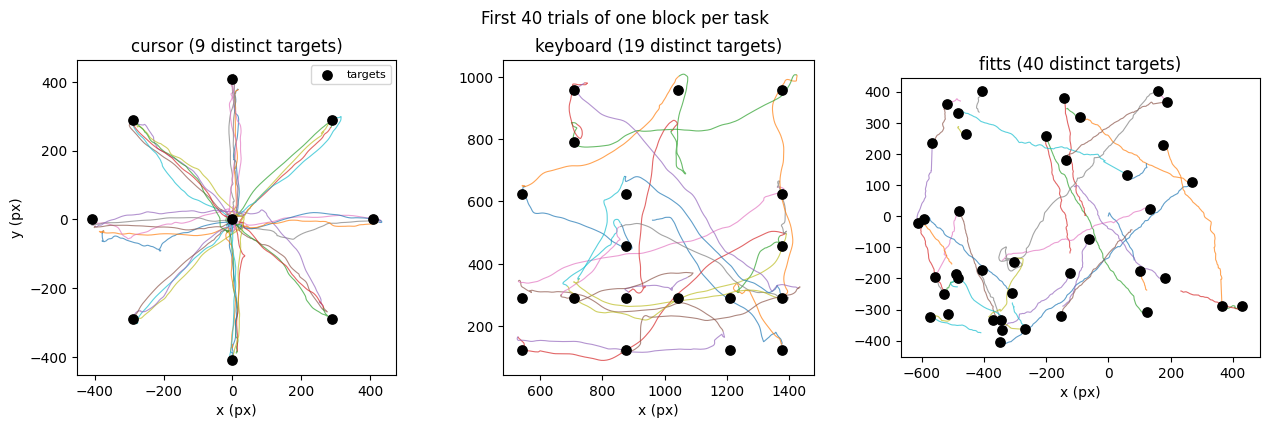

In [8]:
examples = {
    task: next(b for b in blocks if b.task == task) for task in utils.TASK_LABELS
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (task, example) in zip(axes, examples.items()):
    pos = utils.get_series(example, "cursor_position")
    tgt = utils.get_series(example, "target_position")
    trials = utils.trial_windows(example)[:40]
    for start, stop in trials:
        ax.plot(pos[start:stop, 0], pos[start:stop, 1], lw=0.8, alpha=0.7)
    cues = np.unique(np.array([tgt[start] for start, _ in trials]), axis=0)
    ax.scatter(cues[:, 0], cues[:, 1], c="k", s=45, zorder=3, label="targets")
    ax.set_title(f"{task} ({len(cues)} distinct targets)")
    ax.set_xlabel("x (px)")
    ax.set_aspect("equal")
axes[0].set_ylabel("y (px)")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("First 40 trials of one block per task")
fig.tight_layout()

## The undocumented click flag

The source ships a per-block field the upstream README does not describe. It matches the click stream exactly on every released block, so it is a click-enabled flag and `utils.click_enabled` exposes it under that name. Only those blocks emit a click event downstream.

In [9]:
agree = 0
for b in blocks:
    has_click = utils.get_series(b, "decoded_click").max() > 0
    agree += has_click == utils.click_enabled(b)

print(f"blocks where the flag matches the click stream: {agree} / {len(blocks)}")
print(f"click-enabled blocks: {sum(utils.click_enabled(b) for b in blocks)}")

blocks where the flag matches the click stream: 560 / 560


click-enabled blocks: 195


## Signal drift across five years

The point of this dataset is that the neural signal is not stationary. Mean firing rate per channel changes substantially over the 1804 days spanned by the release, which is what forces the repeated decoder recalibration the paper studies.

In [10]:
implant_offsets, mean_rates = [], []
first_day = utils.session_date(sessions[0])
for label, group, path in utils.list_session_files():
    day = utils.session_date(label)
    # Already in Hz, so this averages rates directly.
    rates = utils.load_session(path, label)["threshold_crossings"]
    implant_offsets.append((day - first_day).days)
    mean_rates.append(rates.mean(axis=0))

mean_rates = np.array(mean_rates)
print(f"per-session mean rate matrix: {mean_rates.shape} (sessions x channels)")
print(f"population mean rate: {mean_rates.mean(axis=1).min():.1f} to {mean_rates.mean(axis=1).max():.1f} Hz")

per-session mean rate matrix: (103, 192) (sessions x channels)
population mean rate: 13.7 to 24.9 Hz


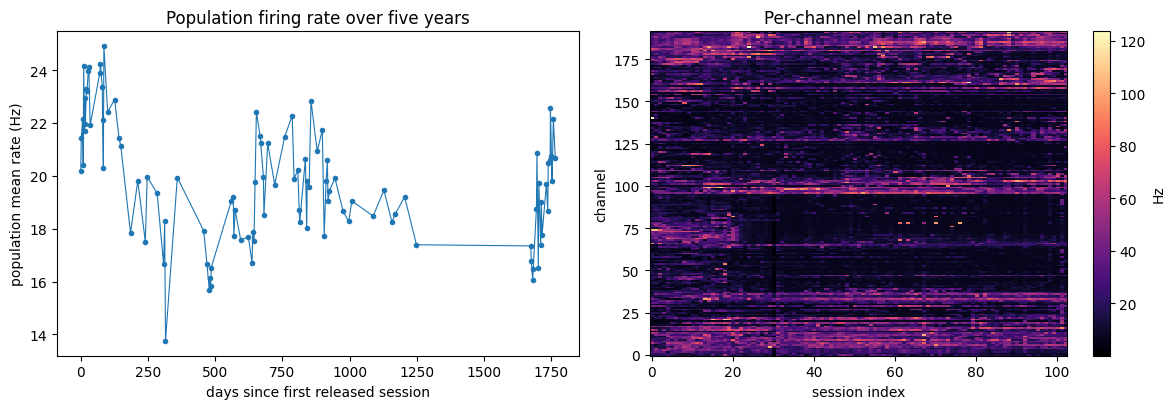

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(implant_offsets, mean_rates.mean(axis=1), "o-", ms=3, lw=0.8)
axes[0].set_xlabel("days since first released session")
axes[0].set_ylabel("population mean rate (Hz)")
axes[0].set_title("Population firing rate over five years")

im = axes[1].imshow(
    mean_rates.T, aspect="auto", origin="lower", interpolation="nearest", cmap="magma"
)
axes[1].set_xlabel("session index")
axes[1].set_ylabel("channel")
axes[1].set_title("Per-channel mean rate")
fig.colorbar(im, ax=axes[1], label="Hz")
fig.tight_layout()

## Two release quirks worth knowing

Both are handled inside `utils`, but they are easy to trip over when reading the raw files directly.

On `t5.2017.08.04` the two pedestal cables were swapped during recording, so channels 0-95 and 96-191 are exchanged relative to every other day. On `t5.2019.01.14` four block numbers appear twice, and the second copy is byte-identical to the first, so roughly 20 minutes of that day is a verbatim duplicate. Only the first copy is exposed, which keeps it out of training data and out of any train/test split.

In [12]:
print("cable-swap days:", sorted(utils.SWAPPED_CABLE_SESSIONS))
print("duplicated-block days:", sorted(utils.DUPLICATED_BLOCK_SESSIONS))

dup = utils.load_session(
    utils.DEFAULT_DATA_DIR / "historical" / "t5.2019.01.14.mat", "t5.2019.01.14"
)
print("\nblock list on t5.2019.01.14:", dup["block_list"].tolist())

raw_counts = dup["threshold_crossings"]
first, second = slice(17839, 32732), slice(98109, 113002)
print("the two copies of block 24 are identical:", np.array_equal(raw_counts[first], raw_counts[second]))
print("blocks exposed for that day:", [b.block for b in blocks if b.session == "t5.2019.01.14"])

cable-swap days: ['t5.2017.08.04']
duplicated-block days: ['t5.2019.01.14']



block list on t5.2019.01.14: [4, 24, 27, 28, 29, 32, 24, 27, 28, 29, 42, 43]
the two copies of block 24 are identical: True
blocks exposed for that day: [4, 24, 27, 28, 29, 32, 42, 43]


## The authors' analysis cohort

The reference code ships a per-day list of the blocks its analyses kept. Selecting the days with at least two such blocks reproduces the paper's 73-session cohort exactly, so `utils` carries that list and the Study stamps every block with whether it belongs.

In [13]:
cohort = utils.analysis_sessions()
print(f"days on disk: {len(sessions)}")
print(f"days with at least two analysis blocks: {len(cohort)}  (paper reports 73)")
print(f"analysis blocks: {sum(b.is_analysis_block for b in blocks)} of {len(blocks)}")

days on disk: 103
days with at least two analysis blocks: 73  (paper reports 73)
analysis blocks: 354 of 560
